<a href="https://colab.research.google.com/github/pradityaputra888-lab/latihan-machine-learning/blob/main/pertemuan8/Bab08_SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 8 — Support Vector Machine (SVM): Hyperplane, Margin, dan Kernel Trick

**Dataset:** Breast Cancer Wisconsin (bawaan Scikit-learn) · **Isi notebook:** Praktikum 8.1–8.6 (kode modul), Latihan Praktikum 1 (Praktikum 8.7), dan Latihan Praktikum 2 (visualisasi decision boundary).

> **Cara pakai di Google Colab:** jalankan sel dari atas ke bawah secara berurutan (*Runtime → Run all*). Latihan memakai variabel dari praktikum sebelumnya (`X_train`, `y_train`, dst.).

## 8.10 Implementasi Python

### Praktikum 8.1 Persiapan Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score

print("Library berhasil dimuat.")

Library berhasil dimuat.


### Praktikum 8.2 Import Dataset

In [2]:
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target

print("Ukuran data :", X.shape)
print("Kelas       :", {str(n): int(c) for n, c in zip(data.target_names, np.bincount(y))})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Data latih / uji:", X_train.shape[0], "/", X_test.shape[0])

Ukuran data : (569, 30)
Kelas       : {'malignant': 212, 'benign': 357}
Data latih / uji: 455 / 114


### Praktikum 8.3 Preprocessing
SVM sangat sensitif terhadap skala fitur, sehingga *scaling* **wajib**. `StandardScaler` dimasukkan ke dalam `Pipeline` agar hanya di-*fit* pada data latih di setiap fold cross-validation (mencegah *data leakage*).

In [3]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC())
])
pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('svm', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'


### Praktikum 8.4 Training Model dengan GridSearchCV

In [4]:
param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": [0.001, 0.01, 0.1, 1],
    "svm__kernel": ["rbf", "linear"]
}
grid_search = GridSearchCV(pipeline, param_grid, cv=5, scoring="f1", n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Parameter terbaik    :", grid_search.best_params_)
print("F1-Score terbaik (CV):", round(grid_search.best_score_, 3))

Parameter terbaik    : {'svm__C': 10, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}
F1-Score terbaik (CV): 0.984


Lima kombinasi parameter terbaik (tambahan, untuk melihat seberapa ketat persaingannya):

In [5]:
cv = pd.DataFrame(grid_search.cv_results_)
kolom = ["param_svm__kernel", "param_svm__C", "param_svm__gamma", "mean_test_score", "std_test_score", "rank_test_score"]
cv[kolom].sort_values("rank_test_score").head(5).round(4)

,param_svm__kernel,param_svm__C,param_svm__gamma,mean_test_score,std_test_score,rank_test_score
18,rbf,10.0,0.010,0.9844,0.0126,1
24,rbf,100.0,0.001,0.9828,0.0120,2
1,linear,0.1,0.001,0.9828,0.0107,3
3,linear,0.1,0.010,0.9828,0.0107,3
7,linear,0.1,1.000,0.9828,0.0107,3


### Praktikum 8.5 Evaluasi

In [6]:
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
print("Akurasi Test:", round(accuracy_score(y_test, y_pred), 3))
print(classification_report(y_test, y_pred, target_names=data.target_names))

Akurasi Test: 0.982


              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



### Praktikum 8.6 Visualisasi — Heatmap F1-Score (kernel RBF)
> **Catatan perbaikan:** pada kode modul, `pivot_table` merata-ratakan *semua* kernel (termasuk linear) padahal judul heatmap menyebut "kernel RBF". Di sini data difilter ke kernel `rbf` saja agar judulnya benar, dan nilai tiap sel ditampilkan.

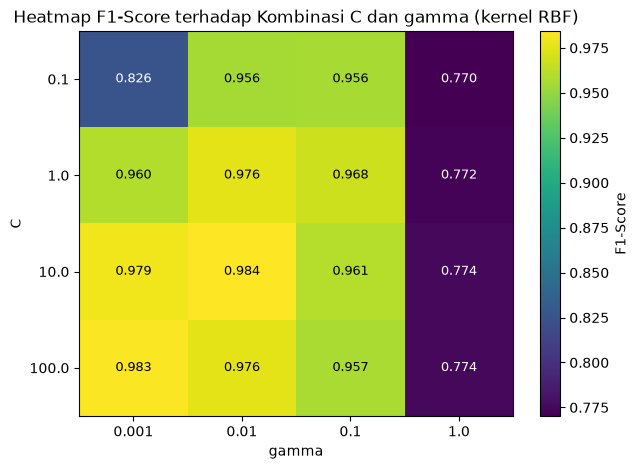

In [7]:
hasil = pd.DataFrame(grid_search.cv_results_)
hasil_rbf = hasil[hasil["param_svm__kernel"] == "rbf"].copy()
hasil_rbf["param_svm__C"] = hasil_rbf["param_svm__C"].astype(float)
hasil_rbf["param_svm__gamma"] = hasil_rbf["param_svm__gamma"].astype(float)

pivot = hasil_rbf.pivot_table(values="mean_test_score",
                              index="param_svm__C", columns="param_svm__gamma")

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(pivot.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(pivot.columns)
ax.set_yticks(range(len(pivot.index)));   ax.set_yticklabels(pivot.index)
ax.set_xlabel("gamma"); ax.set_ylabel("C")
ax.set_title("Heatmap F1-Score terhadap Kombinasi C dan gamma (kernel RBF)")
batas = (pivot.values.min() + pivot.values.max()) / 2
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center",
                color="white" if v < batas else "black", fontsize=9)
plt.colorbar(im, label="F1-Score")
plt.show()

### Interpretasi (Praktikum 8.1–8.6)
- **Hasil tuning:** kombinasi terbaik adalah kernel **RBF dengan C = 10 dan gamma = 0,01** (rata-rata F1 CV = 0,984). Pada data uji model mencapai **akurasi 0,982**, dengan precision, recall, dan F1 di kisaran 0,98–0,99 untuk kedua kelas, sehingga tidak ada kelas yang dikorbankan.
- **Membaca heatmap:** nilai tinggi membentuk pita diagonal. C kecil harus dipasangkan dengan gamma lebih besar, dan C besar dengan gamma lebih kecil (C=10, γ=0,01 → 0,984; C=100, γ=0,001 → 0,983). Dua area terlihat buruk: C=0,1 dengan γ=0,001 (F1 0,826) terlalu sederhana (*underfitting*), sedangkan γ=1 menurunkan F1 ke sekitar 0,77 untuk semua nilai C karena tiap titik hanya memengaruhi area yang sangat sempit, sehingga model menghafal data latih (*overfitting*).
- **Temuan menarik:** kernel linear dengan C=0,1 menghasilkan F1 CV 0,983, hampir sama dengan RBF terbaik (selisih 0,0016, jauh lebih kecil daripada simpangan baku CV ≈ 0,012). Dataset ini hampir terpisah secara linear, sehingga RBF tidak memberi keunggulan yang bermakna.
- **Pelajaran:** C dan gamma harus dituning bersama, bukan sendiri-sendiri, dan *scaling* di dalam `Pipeline` wajib dilakukan agar jarak antarfitur sebanding.

---
## 8.11 Latihan Praktikum

### Latihan 1 — Perbandingan Kernel (Praktikum 8.7)
**Tujuan:** membandingkan kernel linear, polynomial, dan RBF pada dataset yang sama.

In [8]:
# Praktikum 8.7 (kode modul) + F1-Score sebagai pelengkap
from sklearn.metrics import f1_score

hasil_kernel = []
for kernel in ["linear", "poly", "rbf"]:
    model = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel=kernel))])
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    acc = accuracy_score(y_test, pred)
    print(f"Kernel {kernel}: akurasi = {acc:.3f}")
    hasil_kernel.append({"Kernel": kernel,
                         "Akurasi Train": round(model.score(X_train, y_train), 3),
                         "Akurasi Test": round(acc, 3),
                         "F1-Score Test": round(f1_score(y_test, pred), 3),
                         "Jumlah Support Vector": int(model.named_steps["svm"].n_support_.sum())})

pd.DataFrame(hasil_kernel)

Kernel linear: akurasi = 0.974
Kernel poly: akurasi = 0.912
Kernel rbf: akurasi = 0.982


,Kernel,Akurasi Train,Akurasi Test,F1-Score Test,Jumlah Support Vector
0,linear,0.991,0.974,0.979,32
1,poly,0.916,0.912,0.935,145
2,rbf,0.982,0.982,0.986,97


**Analisis Latihan 1:**

| Kernel | Akurasi Test | Catatan |
|---|---|---|
| Linear | 0,974 | Hanya 32 support vector, model paling sederhana dan mudah ditafsirkan |
| Polynomial | 0,912 | Akurasi latih (0,916) juga rendah → *underfitting* pada pengaturan default |
| RBF | 0,982 | Terbaik, 97 support vector |

- **RBF terbaik, tetapi selisihnya tipis.** Dengan 114 data uji, selisih RBF (0,982) dan linear (0,974) hanya **satu sampel**. Secara statistik keduanya setara, sejalan dengan temuan Praktikum 8.6 bahwa data ini hampir terpisah linear.
- **Polynomial paling rendah.** Akurasi latih dan uji sama-sama sekitar 0,91, tandanya model kurang cocok (*underfitting*) dengan pengaturan default (derajat 3, C=1). Kernel ini sensitif terhadap `degree`, `coef0`, dan `gamma`, sehingga perlu tuning sebelum dinilai adil.
- **Pilihan praktis:** gunakan RBF bila ingin akurasi maksimum; gunakan linear bila interpretabilitas dan kecepatan prediksi lebih penting karena support vector-nya jauh lebih sedikit (32 vs 97).

### Latihan 2 — Visualisasi Decision Boundary 2 Fitur
**Instruksi:** pilih 2 fitur dari `load_breast_cancer`, latih SVM dengan beberapa kombinasi kernel/C/gamma, dan visualisasikan decision boundary masing-masing.

Dipilih fitur **`mean radius`** dan **`mean texture`** (dua fitur ini cukup informatif namun tidak memisahkan kelas secara sempurna, sehingga pengaruh parameter terlihat jelas). Warna: **merah = benign (kelas 1)**, **biru = malignant (kelas 0)**. Lingkaran hitam besar menandai *support vector*.

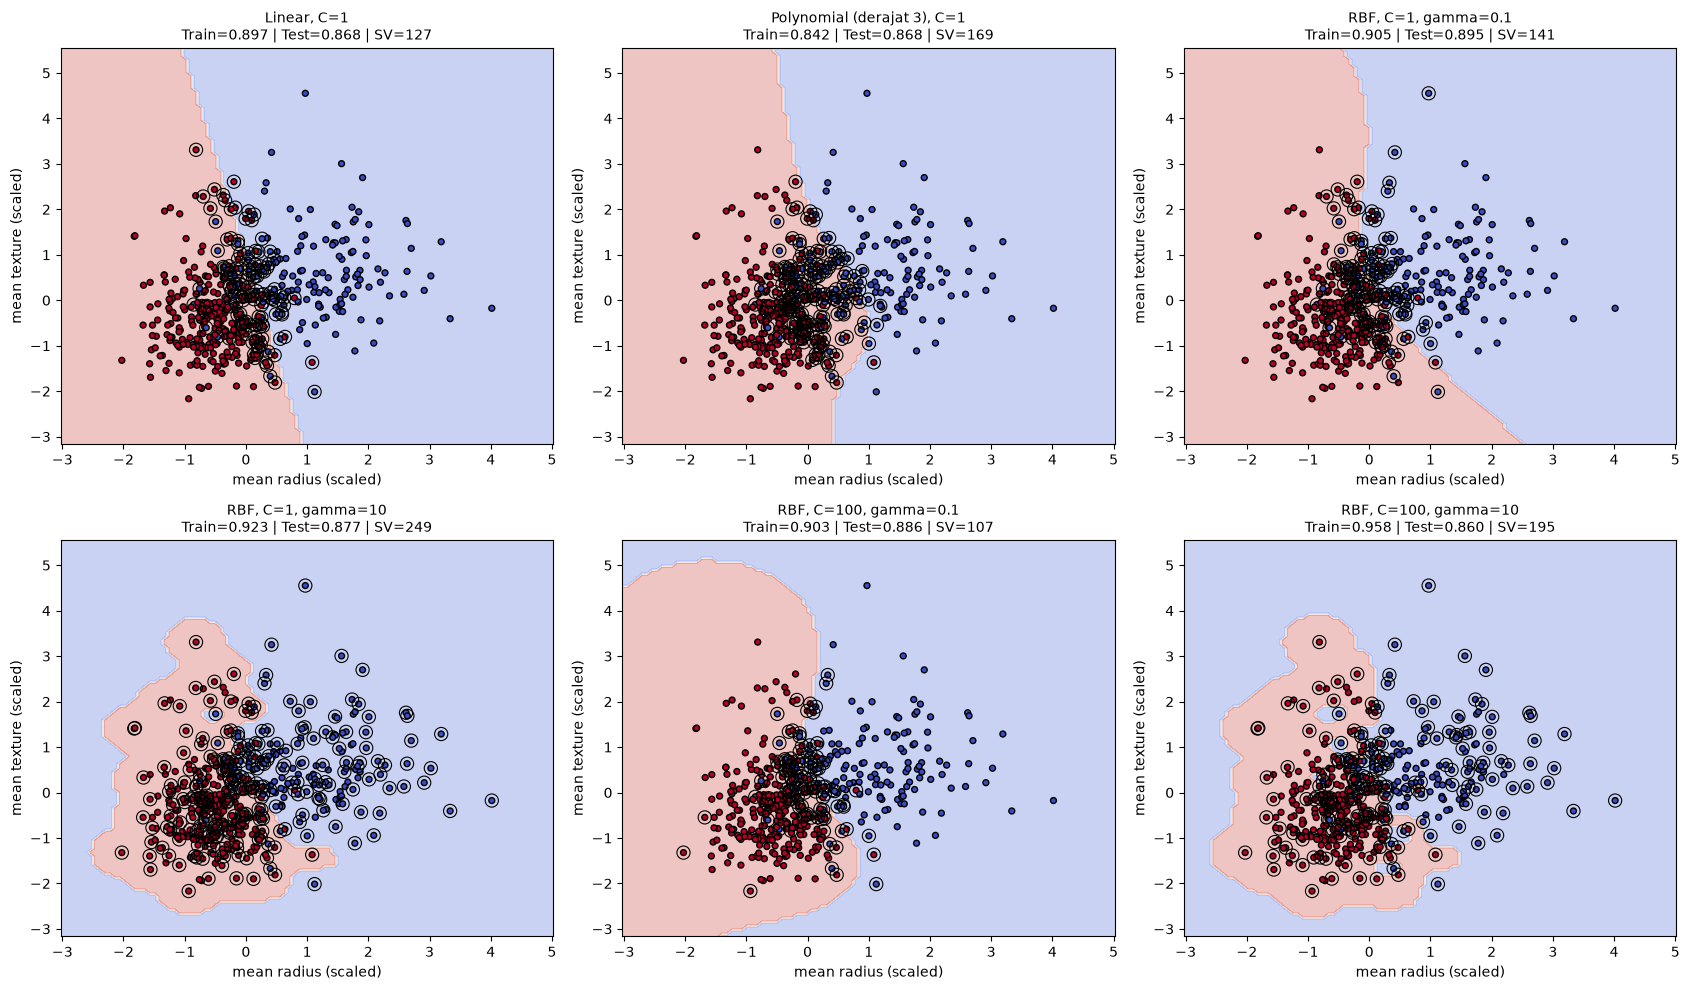

,Konfigurasi,Akurasi Train,Akurasi Test,Gap,Jumlah SV
0,"Linear, C=1",0.897,0.868,0.028,127
1,"Polynomial (derajat 3), C=1",0.842,0.868,-0.027,169
2,"RBF, C=1, gamma=0.1",0.905,0.895,0.011,141
3,"RBF, C=1, gamma=10",0.923,0.877,0.046,249
4,"RBF, C=100, gamma=0.1",0.903,0.886,0.017,107
5,"RBF, C=100, gamma=10",0.958,0.860,0.099,195


In [9]:
from sklearn.inspection import DecisionBoundaryDisplay

fitur = ["mean radius", "mean texture"]
X2 = X[fitur]
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.2, random_state=42, stratify=y)

sc2 = StandardScaler().fit(X2_train)          # scaling hanya di-fit pada data latih
X2_train_s = sc2.transform(X2_train)
X2_test_s = sc2.transform(X2_test)

konfigurasi = [
    ("Linear, C=1",               dict(kernel="linear", C=1)),
    ("Polynomial (derajat 3), C=1", dict(kernel="poly", degree=3, C=1)),
    ("RBF, C=1, gamma=0.1",       dict(kernel="rbf", C=1, gamma=0.1)),
    ("RBF, C=1, gamma=10",        dict(kernel="rbf", C=1, gamma=10)),
    ("RBF, C=100, gamma=0.1",     dict(kernel="rbf", C=100, gamma=0.1)),
    ("RBF, C=100, gamma=10",      dict(kernel="rbf", C=100, gamma=10)),
]

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
ringkasan = []
for ax, (judul, params) in zip(axes.ravel(), konfigurasi):
    clf = SVC(**params).fit(X2_train_s, y2_train)
    acc_tr = clf.score(X2_train_s, y2_train)
    acc_te = clf.score(X2_test_s, y2_test)
    DecisionBoundaryDisplay.from_estimator(
        clf, X2_train_s, response_method="predict",
        cmap=plt.cm.coolwarm, alpha=0.3, ax=ax)
    ax.scatter(X2_train_s[:, 0], X2_train_s[:, 1], c=y2_train,
               cmap=plt.cm.coolwarm, edgecolors="k", s=18)
    ax.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
               s=90, facecolors="none", edgecolors="black", linewidths=0.8)
    ax.set_title(f"{judul}\nTrain={acc_tr:.3f} | Test={acc_te:.3f} | SV={len(clf.support_vectors_)}", fontsize=10)
    ax.set_xlabel(fitur[0] + " (scaled)"); ax.set_ylabel(fitur[1] + " (scaled)")
    ringkasan.append({"Konfigurasi": judul, "Akurasi Train": round(acc_tr, 3),
                      "Akurasi Test": round(acc_te, 3), "Gap": round(acc_tr - acc_te, 3),
                      "Jumlah SV": len(clf.support_vectors_)})
plt.tight_layout()
plt.show()

pd.DataFrame(ringkasan)

**Analisis Latihan 2:**

Lingkaran hitam pada plot adalah support vector. Warna merah = benign, biru = malignant.

**Temuan utama**

1. **Dua fitur tidak cukup.** Akurasi uji terbaik hanya **0,895** (RBF, C=1, γ=0,1), jauh di bawah ≈0,98 ketika 30 fitur dipakai. Kedua kelas bertumpang tindih di tengah plot sehingga kernel apa pun tidak mampu memisahkannya sempurna.
2. **Pengaruh kernel.** Kernel linear (0,868 uji) menghasilkan garis lurus. Polynomial derajat 3 pada data ini bentuknya hampir sama dengan garis lurus (0,868 uji; akurasi latihnya 0,842, bahkan lebih rendah dari uji, tanda *underfitting*). RBF dengan gamma kecil menghasilkan batas yang melengkung halus dan paling baik menggeneralisasi.
3. **Pengaruh gamma.** Gamma besar (γ=10) membuat batas keputusan "melingkari" titik-titik individual membentuk pulau-pulau kecil; jumlah support vector melonjak (141 → 249 pada C=1) dan selisih latih–uji melebar (0,011 → 0,046). Ini tanda *overfitting*.
4. **Pengaruh C.** C besar menekan kesalahan klasifikasi di data latih sehingga batas semakin mengikuti data. Pada γ=0,1, menaikkan C dari 1 ke 100 menurunkan jumlah support vector (141 → 107) dan menggeser batas ke bentuk yang lebih kompleks; akurasi uji turun dari 0,895 ke 0,886. Kombinasi **C=100 dan γ=10 paling berlebihan**: akurasi latih 0,958 tetapi uji 0,860 (selisih 0,099).

**Kesimpulan:** gamma dan C yang moderat menghasilkan batas keputusan yang mulus dan generalisasi paling baik; keduanya yang besar menghasilkan *overfitting*. **Catatan kehati-hatian:** satu sampel uji bernilai ≈0,9 poin persentase, sehingga selisih 0,868–0,895 setara 3 sampel. Yang paling meyakinkan adalah **pola selisih latih–uji dan jumlah support vector**, bukan selisih akurasi uji semata.